# Section 4 · Run quantum circuits

Exam weight: 15% of C1000-179 · about 10 of the 68 questions

## Study path

**Core first pass:** Choose job, batch or session mode; follow the hardware workflow; map observables; recognise PUB fields and all four broadcasting patterns.

- Core coding practice: **4.1–4.6**.
- Optional second pass: **4.7 (construct and analyse a two-dimensional parameter grid) and the marked local-testing implementation question.**
- Core review: answer all questions without an optional label.

Run the setup cell, then work through the unmarked examples in order. Complete a practice starter before running its check cell. At an optional block, use its **continue with the core path** link to skip the entire block; the remaining core cells do not depend on it. Notebook tags `study-core` and `study-optional` also identify the two paths; ordinary **Run All** does not filter tags.

Core/optional labels set a learning priority, not a boundary on what the exam may ask. The [official objectives and sample](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400) remain the coverage reference.

**Jump to:** [Execution modes](#s4-core-3) · [Hardware workflow](#s4-core-30) · [PUBs and broadcasting](#s4-core-53) · [Review](#s4-core-76)

Official objectives
- 4.1 Demonstrate an understanding of execution modes such as: session with dedicated, priority, and batch mode
- 4.2 Demonstrate understanding of how to run quantum circuits with real hardware using Qiskit Runtime primitives and applying broadcasting rules

This notebook maps Part 4.1 to objective 4.1, and Parts 4.2 (hardware workflow) and 4.3 (PUBs and broadcasting) to objective 4.2.

Topics
- choose job, batch or session mode for a workload and state what each one guarantees (dedicated access, prioritized scheduling, ordering, usage, plan limits);
- open, use, close and cancel `Batch` / `Session` objects, with and without context managers, and predict what happens to queued jobs and to the maximum and interactive TTL timers;
- connect with `QiskitRuntimeService`, select a QPU with `least_busy` or `backend`, and prepare ISA circuits plus matching observables;
- run `SamplerV2` / `EstimatorV2` locally on `AerSimulator` (ideal, or a device model built from a fake backend) with exactly the code you would use on hardware;
- predict the result shape of any PUB from NumPy broadcasting rules and name the four canonical broadcasting patterns.

Built from the Qiskit Advocate KR study notebooks `1_Demonstrate_Execution_Modes_KR.ipynb`, `2_Demonstrate_Circuit_Running_RealHW.ipynb` and `Review/Practice_10_Qiskit_Primitives.ipynb` (Q4–Q5), and the QAMP 2025 tutorial (Section 4). Links are in the Sources cell at the end.

In [1]:
import numpy as np

import qiskit
import qiskit_aer
import qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import Batch, EstimatorV2, QiskitRuntimeService, SamplerV2, Session
from qiskit_ibm_runtime.exceptions import IBMInputValueError, IBMRuntimeError
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

np.set_printoptions(precision=3, suppress=True)
print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | "
      f"qiskit-ibm-runtime {qiskit_ibm_runtime.__version__}")

qiskit 2.0.3 | qiskit-aer 0.17.1 | qiskit-ibm-runtime 0.40.1


## Where this section sits: the Qiskit patterns workflow

Every hardware run follows the same four steps: map the problem to circuits and observables, optimize them for the target QPU (transpile to an ISA circuit and move the observables onto the same physical qubits), execute them with a primitive in one of three execution modes, and post-process the `PrimitiveResult`. Section 4 is about step 3, plus the ISA preparation it depends on. Sampler/Estimator options (Sections 5–6) and job retrieval and monitoring (Section 7) are only touched here.

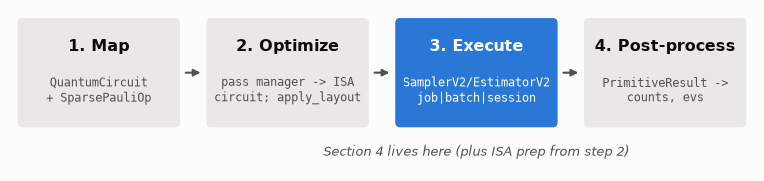

<a id="s4-core-3"></a>

## 4.1 Execution modes: job, batch and session

A QPU is a shared machine. Every workload waits in the QPU's queue, and the execution mode tells the scheduler how to treat a group of your jobs. There are exactly three modes ([Execution modes](https://quantum.cloud.ibm.com/docs/guides/execution-modes)):

| | Job mode | Batch mode | Session mode |
|---|---|---|---|
| How to use | `SamplerV2(mode=backend)` | `Batch(backend=...)` then `mode=batch`, or `with Batch(...):` | `Session(backend=...)` then `mode=session`, or `with Session(...):` |
| Scheduling | each job queues on its own | whole batch scheduled together; once the first job starts, the other batch jobs are prioritized | first job queues; then a dedicated window: the QPU runs only your jobs |
| Exclusive QPU access | no | no: other users' jobs and calibration jobs can run in between | yes, during the active window; no calibration jobs or upgrades interrupt it |
| Job order | independent | not guaranteed | not imposed: jobs submitted together run in parallel; they run one after another only if your code waits for each result |
| Usage (what you pay for) | time the QPU is locked for the job | total time the QPU is locked for the batch's jobs | wall-clock time the session is active, including idle gaps |
| Open Plan | yes | yes | no |
| Typical use | one primitive request (it may hold many PUBs) | many independent jobs whose inputs are all ready | iterative / dependent jobs (VQE, QAOA), inputs that arrive gradually |

Two facts hold for both batch and session: they do not shorten the queue time of the first job, so they bring nothing to a workload made of a single job; and the classical processing of several jobs (five on most backends, the "execution lanes") can run in parallel while the QPU runs one job at a time ([Execution modes FAQ](https://quantum.cloud.ibm.com/docs/guides/execution-modes-faq)).

The picture is a schematic of what the scheduler does with your jobs in each mode (not to scale).

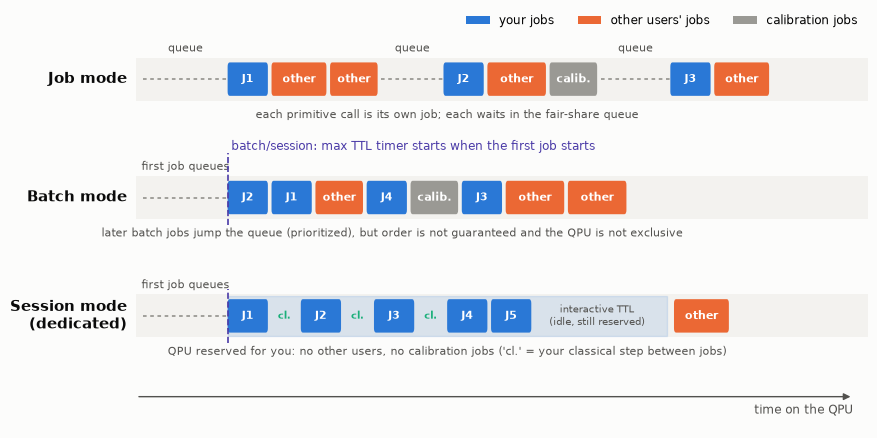

### Dedicated and priority: reading objective 4.1

The objective's wording ("session with dedicated, priority, and batch mode") mirrors how the scheduler evolved:

- Priority (the original sessions). Early Qiskit Runtime sessions only made the scheduler process later session jobs with priority once the first one had started. The QPU was not locked.
- Dedicated (today's session mode). Announced in May 2024 ([IBM Quantum blog, 6 May 2024](https://www.ibm.com/quantum/blog/execution-modes)), sessions now give dedicated QPU access: from the start of the first job, no other users' jobs and no calibration jobs run until the session ends or goes inactive. Sessions "run in dedicated mode": `Session` asks the server for mode `"dedicated"`, and `session.details()["mode"]` reports `'dedicated'`.
- Batch. A batch keeps the priority idea without exclusivity. When its first job starts, the remaining batch jobs "jump to the front of the queue", yet other users' jobs can fill free execution lanes and calibrations can run between batch jobs. `batch.details()["mode"]` reports `'batch'`.
- Fair-share scheduler. Everything outside an active batch or session is ordered by the [fair-share scheduler](https://quantum.cloud.ibm.com/docs/guides/fair-share-scheduler). It serves first the instance that has used the least of its allocation over a rolling window (28 days, per the IBM documentation), and it is first-in-first-out within one instance. Queue priority therefore comes from your instance's allocation and usage, not from the mode you pick.

### Timers: maximum TTL and interactive TTL

| | Maximum TTL (`max_time`) | Interactive TTL |
|---|---|---|
| Who sets it | you: `Session(backend, max_time=...)` or `Batch(backend, max_time=...)`, in seconds (`int`) or as a string such as `"2h 30m 40s"`, below the system maximum | nobody: it cannot be configured |
| When it starts | when the first job starts running (not when the object is created); it never pauses | after each job completes |
| When it runs out | the workload ends: no new jobs, the running job finishes, queued jobs fail | the workload is deactivated (status `Pending`) and normal scheduling resumes. A later job re-activates it, going through the normal queue, as long as the maximum TTL has not been reached |
| Defaults (per the IBM documentation) | session: 8 h (Premium Plan); batch: 8 h on paid plans, 10 min on the Open Plan | session: 60 s (Premium Plan); batch: 1 min on all plans |

Other lifecycle facts ([Run jobs in a session](https://quantum.cloud.ibm.com/docs/guides/run-jobs-session), [Run jobs in a batch](https://quantum.cloud.ibm.com/docs/guides/run-jobs-batch), [Maximum execution time](https://quantum.cloud.ibm.com/docs/guides/max-execution-time)):

| Event | New jobs | Queued jobs | Running job |
|---|---|---|---|
| `close()`, or leaving the `with` block | rejected | run to completion | completes |
| `cancel()` | rejected | cancelled | (docs only speak of pending jobs) |
| maximum TTL reached | rejected | fail | completes |

- `session.status()` returns one of `Pending`, `In progress, accepting new jobs`, `In progress, not accepting new jobs`, `Closed`.
- Per the IBM documentation, a session that receives no job for 30 minutes after being opened closes automatically. A batch also ends by itself after its last job, but you should still close batches and sessions explicitly.
- The idle interactive-TTL time after a session job counts as usage. Close a session as soon as you have submitted its last job.
- `details()["interactive_timeout"]` is reported in seconds (per the `Session.details` docstring). The batch guide describes the batch value as 1 minute. The exam-relevant fact is only that the interactive TTL cannot be configured.

### Open Plan versus paid plans

| Plan | QPU access | Execution modes |
|---|---|---|
| Open Plan (free) | up to 10 QPU minutes per rolling 28-day window | job and batch only; no sessions |
| Paid plans (the current IBM documentation lists Flex, Pay-As-You-Go, Premium, On-Prem) | purchased or contracted time (Flex: pre-purchased minutes; Pay-As-You-Go: pay for what you use; Premium: enterprise subscription; On-Prem: a dedicated on-site system) | job, batch and session |

Sources: [Plans overview](https://quantum.cloud.ibm.com/docs/guides/plans-overview), [Run jobs in a session](https://quantum.cloud.ibm.com/docs/guides/run-jobs-session).

`max_time` is not counted from the moment you create the `Session`/`Batch` object; it starts with the first job. The interactive TTL cannot be changed from Qiskit. `close()` does not cancel anything: submitted jobs still run. Only `cancel()` (or reaching the maximum TTL) throws queued jobs away.

Common trap: Two different "10 minutes" belong to the Open Plan. The usage quota is 10 QPU minutes per rolling 28-day window, summed over all your workloads. The default maximum TTL of an Open Plan batch is also 10 minutes, but it is the wall-clock lifetime of one batch, counted from its first job. One is a rolling-window allowance of QPU time, the other a timer on a single batch.

### Execution modes in code (local testing mode)

When `mode` is a local backend such as `AerSimulator`, the Runtime primitives run on your laptop in local testing mode. The `Session` and `Batch` syntax is accepted, but there is no scheduler, so the modes themselves are ignored ([Execution modes FAQ](https://quantum.cloud.ibm.com/docs/guides/execution-modes-faq)). The code is exactly what you would run against a QPU. Part 4.1 uses the ideal `AerSimulator()`; Part 4.2 switches to a noisy device model. First, a backend and two circuits transpiled for it (ISA transpilation is explained in 4.2). Then job mode: pass the backend itself as `mode`; one `run()` call is one job, and it may carry many PUBs.

In [2]:
backend = AerSimulator()     # ideal local simulator; stands in for a QPU in these mode demos
pm = generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=7)

bell = QuantumCircuit(2, name="bell")
bell.h(0)
bell.cx(0, 1)
bell.measure_all()
flip = QuantumCircuit(2, name="flip")
flip.x(0)
flip.measure_all()
isa_bell, isa_flip = pm.run([bell, flip])     # versions transpiled for this backend
print(backend.name, "| bell ops:", dict(isa_bell.count_ops()))

aer_simulator | bell ops: {'measure': 2, 'h': 1, 'cx': 1, 'barrier': 1}


In [3]:
sampler = SamplerV2(mode=backend)                 # job mode
sampler.options.default_shots = 1000
sampler.options.simulator.seed_simulator = 42     # reproducible local simulation
job = sampler.run([isa_bell, isa_flip])           # ONE job with TWO PUBs
print("sampler.mode:", sampler.mode)              # None means job mode
for pub_result in job.result():
    print(pub_result.data.meas.get_counts())      # 'flip' gives '01': qubit 0 is the rightmost bit

sampler.mode: None
{'11': 490, '00': 510}
{'01': 1000}


Batch mode with a context manager. A primitive created inside the `with` block without a `mode` picks up the open batch. Each `run()` is a separate job, and leaving the block calls `batch.close()`:

In [4]:
with Batch(backend=backend, max_time="10m") as batch:
    batch_sampler = SamplerV2()                   # no mode: uses the open batch
    batch_sampler.options.default_shots = 1000
    batch_sampler.options.simulator.seed_simulator = 42
    batch_jobs = [batch_sampler.run([circ]) for circ in (isa_bell, isa_flip)]  # 2 independent jobs
    print("mode:", type(batch_sampler.mode).__name__, "| is our batch:", batch_sampler.mode is batch)

# the batch is closed now, but jobs submitted before close() still finish
print([j.result()[0].data.meas.get_counts() for j in batch_jobs])
print("Batch is a subclass of Session:", issubclass(Batch, Session))

mode: Batch | is our batch: True
[{'11': 490, '00': 510}, {'01': 1000}]
Batch is a subclass of Session: True


Session mode without a context manager: an iterative loop. Each iteration needs the previous result, so this is session territory. We minimise $\langle Z\rangle = \cos\theta$ of $R_Y(\theta)|0\rangle$ with the parameter-shift gradient $\partial_\theta\langle Z\rangle = \tfrac12[\langle Z\rangle_{\theta+\pi/2} - \langle Z\rangle_{\theta-\pi/2}]$. Both shifted points travel in one PUB, so each iteration costs one job:

In [5]:
theta = Parameter("θ")
ansatz = QuantumCircuit(1)
ansatz.ry(theta, 0)
isa_ansatz = pm.run(ansatz)
isa_z = SparsePauliOp("Z").apply_layout(isa_ansatz.layout)

session = Session(backend=backend)                # no context manager: we must close it
estimator = EstimatorV2(mode=session)
estimator.options.simulator.seed_simulator = 1

x = 0.3
for step in range(6):
    pub = (isa_ansatz, isa_z, [[x + np.pi / 2], [x - np.pi / 2]])   # 2 parameter sets -> evs.shape (2,)
    e_plus, e_minus = estimator.run([pub]).result()[0].data.evs
    x -= 0.8 * (e_plus - e_minus) / 2             # the next job depends on this result
    print(f"step {step}: θ = {x:.3f}   (exact <Z> at this θ: {np.cos(x):+.3f})")
session.close()                                   # stop accepting jobs as soon as you are done

try:
    estimator.run([(isa_ansatz, isa_z, [x])])     # submitting to a closed session
except IBMRuntimeError as err:
    print("IBMRuntimeError:", err)

# In local testing mode nothing is created on the server:
print("session_id:", session.session_id, "| details():", session.details())

step 0: θ = 0.558   (exact <Z> at this θ: +0.848)
step 1: θ = 0.999   (exact <Z> at this θ: +0.541)
step 2: θ = 1.673   (exact <Z> at this θ: -0.102)
step 3: θ = 2.469   (exact <Z> at this θ: -0.782)
step 4: θ = 2.977   (exact <Z> at this θ: -0.987)
step 5: θ = 3.133   (exact <Z> at this θ: -1.000)
IBMRuntimeError: 'The session is closed.'
session_id: None | details(): None


In [6]:
# Where the primitive is created matters: a primitive built OUTSIDE the with-block keeps the
# mode it was given (job mode here). `mode` must be a backend, Session or Batch OBJECT.
# (Local-mode detail in runtime 0.40.1: the mode-less primitive re-fetches the backend by name,
#  which works for AerSimulator() and fake backends but not for AerSimulator.from_backend(...);
#  pass mode=session / mode=batch explicitly there.)
outside = SamplerV2(mode=backend)                 # created before the with-block
with Session(backend=backend) as session2:
    inside = SamplerV2()                          # created inside: joins the session
    print("outside.mode:", outside.mode, "| inside.mode is session2:", inside.mode is session2)

for bad in (lambda: SamplerV2(), lambda: SamplerV2(mode="ibm_torino")):
    try:
        bad()
    except ValueError as err:
        print("ValueError:", err)

outside.mode: None | inside.mode is session2: True
ValueError: A backend or session must be specified.
ValueError: mode must be of type Backend, Session, Batch or None


In [7]:
# The same calls against real hardware, guarded so that the notebook runs without credentials.
# Example outputs from the IBM documentation:
#   batch.details()   -> {'id': ..., 'backend_name': 'ibm_marrakesh', 'interactive_timeout': 1,
#                         'max_time': 28800, 'state': 'open', 'accepting_jobs': True, ..., 'mode': 'batch', ...}
#   session.details() -> {'id': ..., 'backend_name': 'ibm_marrakesh', 'interactive_timeout': 60,
#                         'max_time': 28800, 'state': 'open', 'accepting_jobs': True, ..., 'mode': 'dedicated', ...}
USE_REAL_HARDWARE = False   # True needs a saved IBM Quantum Platform account (sessions need a paid plan)

if USE_REAL_HARDWARE:
    service = QiskitRuntimeService()                          # default saved account
    qpu = service.least_busy(operational=True, simulator=False)
    with Batch(backend=qpu, max_time="5m") as real_batch:
        print(real_batch.details()["mode"], real_batch.details()["max_time"])  # 'batch', 300
    with Session(backend=qpu) as real_session:               # raises on the Open Plan
        print(real_session.status(), real_session.details()["mode"])          # 'Pending' 'dedicated'
else:
    print("USE_REAL_HARDWARE is False: cloud calls skipped.")

USE_REAL_HARDWARE is False: cloud calls skipped.


### Choosing a mode

| Situation | Mode |
|---|---|
| One primitive request, even with many PUBs | job |
| Several independent jobs, all inputs ready (compare mitigation settings, a large sweep split into chunks) | batch |
| Job k+1 depends on the result of job k (VQE/QAOA with a classical optimizer) | session |
| You must reuse something that goes stale in the queue, for example a noise model learned once for PEA/PEC | session |
| Open Plan instance | job or batch (sessions are not available) |

Default to batch unless you need what only a session provides, because sessions are generally more expensive ([Choose the right execution mode](https://quantum.cloud.ibm.com/docs/guides/choose-execution-mode)). Independently of the mode, if each job uses less than about one minute of QPU time, combine several into one larger job: every job carries a fixed overhead.

"Batch is cheaper and faster, so it is always better" is wrong for iterative algorithms. In batch mode every optimizer step goes back through the queue, the device can drift between steps, and nothing stops other jobs from running in between. The opposite trap: opening a session on the Open Plan raises an error.

### Practice 4.1 — Run independent jobs in a batch

Three basis-state circuits are prepared below for `ex1_backend`, an ideal `AerSimulator`.

1. Open a `Batch` on `ex1_backend` with a context manager and `max_time="15m"`.
2. Inside the block create `ex1_sampler = SamplerV2()` without `mode`, set `default_shots = 500` and `simulator.seed_simulator = 3`.
3. Submit each circuit as its own job and collect the jobs in the list `ex1_jobs`.
4. After the block, store the most frequent bitstring of each job in `ex1_top` (a list of 3 strings).

In [ ]:
ex1_backend = AerSimulator()
ex1_pm = generate_preset_pass_manager(optimization_level=1, backend=ex1_backend, seed_transpiler=3)
ex1_circuits = []
for flips in ([0], [1], [0, 1]):          # prepares |01>, |10>, |11> (qubit 0 = rightmost bit)
    c = QuantumCircuit(2)
    c.x(flips)
    c.measure_all()
    ex1_circuits.append(c)
ex1_isa = ex1_pm.run(ex1_circuits)

ex1_sampler = None     # TODO: create inside a `with Batch(...)` block, no mode argument
ex1_jobs = []          # TODO: one job per circuit
ex1_top = None         # TODO: most frequent bitstring of each job (after the block)

In [ ]:
# Run this cell to check your answer
assert ex1_sampler is not None and isinstance(ex1_sampler.mode, Batch), \
    "create the sampler inside the with-block, without mode="
assert len(ex1_jobs) == 3, "submit one job per circuit"
assert all(j.result()[0].data.meas.num_shots == 500 for j in ex1_jobs), "use 500 shots"
assert ex1_top == ["01", "10", "11"], ex1_top
try:
    ex1_sampler.run([ex1_isa[0]])
    batch_closed = False
except IBMRuntimeError:
    batch_closed = True
assert batch_closed, "the batch should be closed after the with-block"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex1_backend = AerSimulator()
ex1_pm = generate_preset_pass_manager(optimization_level=1, backend=ex1_backend, seed_transpiler=3)
ex1_circuits = []
for flips in ([0], [1], [0, 1]):
    c = QuantumCircuit(2)
    c.x(flips)
    c.measure_all()
    ex1_circuits.append(c)
ex1_isa = ex1_pm.run(ex1_circuits)

with Batch(backend=ex1_backend, max_time="15m"):
    ex1_sampler = SamplerV2()
    ex1_sampler.options.default_shots = 500
    ex1_sampler.options.simulator.seed_simulator = 3
    ex1_jobs = [ex1_sampler.run([c]) for c in ex1_isa]

ex1_top = []
for j in ex1_jobs:
    counts = j.result()[0].data.meas.get_counts()
    ex1_top.append(max(counts, key=counts.get))
print(ex1_top)
```

The primitive picks up the open batch because it is created inside the `with` block with no `mode`. Three `run()` calls give three jobs that the scheduler treats as one batch. Leaving the block calls `close()`, so a fourth job is refused with `IBMRuntimeError`, while the three submitted jobs still finish. Bitstrings are little-endian: `x(0)` gives `'01'`.

</details>

### Practice 4.2 — Open, use and close a session by hand

1. Open `ex2_session = Session(...)` on `ex2_backend` without a context manager.
2. Create `ex2_estimator` in that session and set `options.simulator.seed_simulator = 7`.
3. For `theta` in `(0, np.pi/2, np.pi)` submit one job per value that estimates $\langle Z\rangle$ of $R_X(\theta)|0\rangle$, and append the value as a `float` to `ex2_evs`.
4. Close the session.

In [ ]:
ex2_backend = AerSimulator.from_backend(FakeManilaV2())   # noisy device model
ex2_theta = Parameter("θ")
ex2_qc = QuantumCircuit(1)
ex2_qc.rx(ex2_theta, 0)
ex2_isa = generate_preset_pass_manager(optimization_level=1, backend=ex2_backend,
                                       seed_transpiler=7).run(ex2_qc)
ex2_obs = SparsePauliOp("Z").apply_layout(ex2_isa.layout)

ex2_session = None     # TODO
ex2_estimator = None   # TODO
ex2_evs = []
# TODO: loop over theta, one job each, append float(<Z>)
# TODO: close the session

In [ ]:
# Run this cell to check your answer
assert isinstance(ex2_session, Session) and not isinstance(ex2_session, Batch), \
    "open ex2_session with Session(backend=ex2_backend)"
assert ex2_estimator.mode is ex2_session, "pass mode=ex2_session"
assert len(ex2_evs) == 3 and np.allclose(ex2_evs, [1, 0, -1], atol=0.2), ex2_evs
try:
    ex2_estimator.run([(ex2_isa, ex2_obs, [0.0])])
    session_closed = False
except IBMRuntimeError:
    session_closed = True
assert session_closed, "close the session when you are done"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_backend = AerSimulator.from_backend(FakeManilaV2())   # noisy device model
ex2_theta = Parameter("θ")
ex2_qc = QuantumCircuit(1)
ex2_qc.rx(ex2_theta, 0)
ex2_isa = generate_preset_pass_manager(optimization_level=1, backend=ex2_backend,
                                       seed_transpiler=7).run(ex2_qc)
ex2_obs = SparsePauliOp("Z").apply_layout(ex2_isa.layout)

ex2_session = Session(backend=ex2_backend)
ex2_estimator = EstimatorV2(mode=ex2_session)
ex2_estimator.options.simulator.seed_simulator = 7
ex2_evs = []
for theta in (0, np.pi / 2, np.pi):
    ev = ex2_estimator.run([(ex2_isa, ex2_obs, [theta])]).result()[0].data.evs
    ex2_evs.append(float(ev))
ex2_session.close()
print(ex2_evs)
```

$\langle Z\rangle = \cos\theta$ gives $1, 0, -1$ up to shot noise and the noise of the device model. Without a context manager nothing closes the session for you. On hardware an open session keeps the QPU reserved and its idle time is billed. `Batch` is a subclass of `Session`, which is why the check excludes it explicitly.

</details>

Q4.1. An Open Plan user must run 40 Estimator jobs that compare different error-mitigation settings on the same circuit. All inputs are ready before anything is submitted, and each job needs its own options. Which execution mode is the best fit?

A. Session mode, because the jobs belong to one experiment

B. Batch mode

C. Job mode, submitting each job and waiting for its result before submitting the next

D. Session mode with `max_time` set to 10 minutes to keep the cost down

<details>
<summary>Show answer</summary>

Answer: B

The jobs are independent and all ready, which is exactly what batch mode is for: they are scheduled together, their classical pre-processing runs in parallel, and they run close to each other in time, which helps a fair comparison. Sessions (A, D) are not available on the Open Plan at all, and they only pay off when jobs depend on each other. Submitting one job at a time in job mode (C) sends every job back through the queue.

</details>

Q4.2. `backend` is a valid `IBMBackend` and `pub1`, `pub2` are valid ISA PUBs. What happens?

```python
session = Session(backend=backend)
estimator = EstimatorV2(mode=session)
job1 = estimator.run([pub1])
session.close()
job2 = estimator.run([pub2])
```

A. `job2` silently runs in job mode because the session is closed

B. `session.close()` cancels `job1`; `job2` opens a new session automatically

C. `job1` still runs to completion; submitting `job2` raises `IBMRuntimeError: 'The session is closed.'`

D. `job2` is queued and runs when the interactive TTL expires

<details>
<summary>Show answer</summary>

Answer: C

`close()` stops the session from accepting new jobs but lets queued and running jobs finish, so `job1` completes. The client marks the session inactive, and the next `run()` raises `IBMRuntimeError('The session is closed.')` (verified in local mode). There is no automatic fallback to job mode (A) and no automatic re-opening (B). Cancelling queued jobs is what `cancel()` does, not `close()`.

</details>

Q4.3. Which two statements about the timers of batches and sessions are correct? (Select two.)

A. When the maximum TTL is reached, a job that is already running finishes, but jobs still queued in the workload fail.

B. The interactive TTL can be extended with `Session(backend, interactive_ttl=300)`.

C. The maximum TTL starts counting when the `Session` or `Batch` object is created.

D. If no job arrives within the interactive TTL, the workload is deactivated; a later job can re-activate it (after going through the normal queue) while the maximum TTL has not been reached.

E. `max_time` accepts only an integer number of seconds; `max_time="1h"` raises an error.

<details>
<summary>Show answer</summary>

Answer: A, D

A and D follow the official basic workflow. B is false: the interactive TTL cannot be configured, and `Session.__init__` has no such parameter. C is false: the timer starts when the first job starts running. E is false: `max_time` takes seconds or a string such as `"1h"` or `"2h 30m 40s"` (`Session(backend, max_time="1h")` stores 3600 s).

</details>

<a id="s4-core-30"></a>

## 4.2 Running circuits on real hardware with Qiskit Runtime primitives

A hardware run has five steps: authenticate with `QiskitRuntimeService` → choose a QPU → transpile to an ISA circuit and map the observables → submit with `SamplerV2`/`EstimatorV2` in a mode → retrieve the `PrimitiveResult`.

### Authenticate and choose a backend

```python
from qiskit_ibm_runtime import QiskitRuntimeService

# once per machine: stores the credentials in ~/.qiskit/qiskit-ibm.json
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",        # the default channel ("ibm_cloud" is also accepted)
    token="<your IBM Cloud API key>",      # keep it out of shared notebooks
    instance="<instance CRN or name>",     # optional: otherwise an instance is selected for you
    name="my-account", set_as_default=True, overwrite=True,
)
service = QiskitRuntimeService()           # loads the default saved account
# without saving: QiskitRuntimeService(channel="ibm_quantum_platform", token="...", instance="...")

service.backends(simulator=False, operational=True, min_num_qubits=100)  # list of IBMBackend
backend = service.least_busy(operational=True, simulator=False, min_num_qubits=127)
backend = service.backend("ibm_torino")    # a specific QPU by name
```

| Call | Returns / purpose |
|---|---|
| `QiskitRuntimeService.save_account(...)` | class method; saves `token`, `instance`, `channel`, … under a `name` |
| `QiskitRuntimeService()` | service built from the default saved account |
| `service.backends(**filters)` | a list of backends matching `min_num_qubits=...`, `operational=True`, `simulator=False`, `filters=lambda b: ...` |
| `service.least_busy(min_num_qubits=..., **filters)` | the matching backend with the fewest pending jobs |
| `service.backend("name")` | one backend by name (no filters) |

Use `channel="ibm_quantum_platform"` (the default). The legacy `channel="ibm_quantum"` was retired together with the old IBM Quantum Platform on 1 July 2025. qiskit-ibm-runtime 0.40.1 still accepts the string and only emits a deprecation warning, but the service behind it is gone ([Save your login credentials](https://quantum.cloud.ibm.com/docs/guides/save-credentials), [Plans overview](https://quantum.cloud.ibm.com/docs/guides/plans-overview)). The special value `channel="local"` returns an offline service that serves fake backends:

In [8]:
local_service = QiskitRuntimeService(channel="local")      # no credentials needed
print(type(local_service).__name__)
fake = local_service.backend("fake_manila")                # same call shape as service.backend("ibm_...")
print(fake.name, fake.num_qubits, "qubits | native ops:", sorted(fake.operation_names)[:8])

QiskitRuntimeLocalService
fake_manila 5 qubits | native ops: ['cx', 'delay', 'for_loop', 'id', 'if_else', 'measure', 'reset', 'rz']


### ISA circuits: the primitives only accept hardware-ready circuits

An ISA circuit (instruction set architecture) uses only the operations in the backend's `Target`, acts only on physically connected qubit pairs, and is written on the device's physical qubits. Since 1 March 2024 the Runtime primitives reject non-ISA circuits. The check happens in `run()`, not in the constructor. The cell below shows it in local testing mode with a fake backend as `mode`, which raises the same `IBMInputValueError` as a QPU. An `AerSimulator` counts as a simulator, so Runtime skips this check for it; the device model built from the same fake backend then fails inside Aer with an `AerError` instead. Aer checks instruction names only, not the coupling map, so it cannot prove that a circuit is ISA.

In [9]:
ghz = QuantumCircuit(3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
ghz.measure_all()

fake_manila = FakeManilaV2()                     # snapshot of a 5-qubit IBM QPU
checked = SamplerV2(mode=fake_manila)            # constructing the primitive is fine...
try:
    checked.run([ghz])                           # ...running a non-ISA circuit is not
except IBMInputValueError as err:
    print("IBMInputValueError:", str(err).split(" Circuits")[0])

device = AerSimulator.from_backend(fake_manila)  # noisy device model used from here on
try:
    SamplerV2(mode=device).run([ghz]).result()
except Exception as err:                          # Aer's own error, not the Runtime ISA check
    print(type(err).__name__ + ":", err)

IBMInputValueError: 'The instruction h on qubits (0,) is not supported by the target system.


AerError: 'unknown instruction: h'


operations      : {'measure': 3, 'rz': 2, 'cx': 2, 'sx': 1, 'barrier': 1}
virtual->physical: [0, 1, 2]


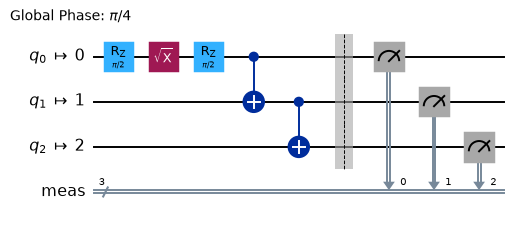

In [10]:
device_pm = generate_preset_pass_manager(optimization_level=1, backend=device, seed_transpiler=7)
isa_ghz = device_pm.run(ghz)
print("operations      :", dict(isa_ghz.count_ops()))
print("virtual->physical:", isa_ghz.layout.final_index_layout())
isa_ghz.draw("mpl", idle_wires=False, fold=-1, scale=0.7)

In [11]:
hw_sampler = SamplerV2(mode=device)
hw_sampler.options.default_shots = 2000
hw_sampler.options.simulator.seed_simulator = 11
counts = hw_sampler.run([isa_ghz]).result()[0].data.meas.get_counts()
print(sorted(counts.items(), key=lambda kv: -kv[1])[:4])
print("P(000) + P(111) =", (counts.get("000", 0) + counts.get("111", 0)) / 2000)

[('000', 863), ('111', 804), ('100', 102), ('011', 97)]
P(000) + P(111) = 0.8335


### Observables must follow the layout

After transpilation the circuit acts on all 5 physical qubits and the logical qubits may have moved. An `EstimatorV2` PUB therefore needs observables on the same physical qubits: `obs.apply_layout(isa_circuit.layout)`. The Estimator circuit carries no measurements.

In [12]:
bell_state = QuantumCircuit(2)
bell_state.h(0)
bell_state.cx(0, 1)
isa_bell_state = device_pm.run(bell_state)
observables = [SparsePauliOp(p) for p in ("ZZ", "XX", "YY", "ZI")]

try:
    EstimatorV2(mode=device).run([(isa_bell_state, observables)])
except ValueError as err:
    print("ValueError:", err)

isa_observables = [obs.apply_layout(isa_bell_state.layout) for obs in observables]
print("mapped ZZ:", isa_observables[0].paulis[0], "on", isa_observables[0].num_qubits, "qubits")

hw_estimator = EstimatorV2(mode=device)
hw_estimator.options.simulator.seed_simulator = 5
est_result = hw_estimator.run([(isa_bell_state, isa_observables)]).result()
print("evs  (ideal 1, 1, -1, 0):", est_result[0].data.evs)
print("stds:", est_result[0].data.stds)
print("metadata:", est_result[0].metadata)

ValueError: The number of qubits of the circuit (5) does not match the number of qubits of the (0,)-th observable (2).
mapped ZZ: IIIZZ on 5 qubits


evs  (ideal 1, 1, -1, 0): [ 0.875  0.871 -0.885  0.01 ]
stds: [0.008 0.008 0.007 0.016]
metadata: {'target_precision': 0.015625, 'shots': 4096, 'circuit_metadata': {}}


Forgetting `apply_layout` gives a `ValueError` saying that the number of qubits of the circuit (5) does not match the number of qubits of the observable (2). Writing the padded Pauli string by hand, for example `"IIIZZ"`, only works while the layout happens to be the trivial one. Always map with the layout of the circuit you actually submit.

### From local test to hardware: change one object

The local runs above are the real workflow; only the object passed as `mode` differs. With credentials, the guarded cell below does the same thing on a QPU. A result is a `PrimitiveResult`: `result[i]` is the `PubResult` of PUB i, and its `data` holds one `BitArray` per classical register (Sampler, `data.meas` for `measure_all`) or `evs` / `stds` arrays (Estimator). Job status, retrieval by ID and monitoring are covered in Section 7.

In [13]:
if USE_REAL_HARDWARE:
    service = QiskitRuntimeService()
    qpu = service.least_busy(operational=True, simulator=False, min_num_qubits=5)
    isa_qpu = generate_preset_pass_manager(optimization_level=1, backend=qpu).run(ghz)
    qpu_job = SamplerV2(mode=qpu).run([isa_qpu], shots=2000)     # job mode on the QPU
    print(qpu.name, qpu_job.job_id(), qpu_job.status())
    print(qpu_job.result()[0].data.meas.get_counts())
else:
    print("USE_REAL_HARDWARE is False: the device-model run above stands in for the QPU run.")

USE_REAL_HARDWARE is False: the device-model run above stands in for the QPU run.


Exam tip: Choose where a primitive runs with `mode=`: a backend object (job mode), a `Session`, or a `Batch`. The old keywords `backend=` and `session=` were deprecated in qiskit-ibm-runtime 0.24 in favour of `mode=` and removed in 0.30, so `SamplerV2(backend=...)` raises `TypeError`. `from qiskit_ibm_runtime import SamplerV2 as Sampler` is the usual alias (`qiskit_ibm_runtime.Sampler` is the same class).

### Practice 4.3 — Make a GHZ circuit hardware-ready and sample it

1. Transpile `ex3_qc` for `ex3_backend` with `generate_preset_pass_manager(optimization_level=1, backend=..., seed_transpiler=5)` and store the result in `ex3_isa`.
2. Run it with `SamplerV2` in job mode, with 4000 shots and `simulator.seed_simulator = 5`. Store the counts dictionary in `ex3_counts`.

In [ ]:
ex3_backend = AerSimulator.from_backend(FakeManilaV2())   # noisy device model
ex3_qc = QuantumCircuit(4)
ex3_qc.h(0)
for q in range(3):
    ex3_qc.cx(q, q + 1)
ex3_qc.measure_all()

ex3_isa = None       # TODO
ex3_counts = None    # TODO

In [ ]:
# Run this cell to check your answer
assert ex3_isa is not None and ex3_isa.num_qubits == ex3_backend.num_qubits, "transpile for the backend"
allowed = set(ex3_backend.operation_names) | {"barrier"}
assert set(ex3_isa.count_ops()) <= allowed, set(ex3_isa.count_ops()) - allowed
assert sum(ex3_counts.values()) == 4000, "use 4000 shots"
ghz_fraction = (ex3_counts.get("0000", 0) + ex3_counts.get("1111", 0)) / 4000
assert ghz_fraction > 0.7, ghz_fraction
print(f"GHZ fraction {ghz_fraction:.3f}. Correct!")

<details>
<summary>Show solution</summary>

```python
ex3_backend = AerSimulator.from_backend(FakeManilaV2())   # noisy device model
ex3_qc = QuantumCircuit(4)
ex3_qc.h(0)
for q in range(3):
    ex3_qc.cx(q, q + 1)
ex3_qc.measure_all()

ex3_pm = generate_preset_pass_manager(optimization_level=1, backend=ex3_backend, seed_transpiler=5)
ex3_isa = ex3_pm.run(ex3_qc)
ex3_sampler = SamplerV2(mode=ex3_backend)
ex3_sampler.options.default_shots = 4000
ex3_sampler.options.simulator.seed_simulator = 5
ex3_counts = ex3_sampler.run([ex3_isa]).result()[0].data.meas.get_counts()
```

The pass manager rewrites `h` into `rz`/`sx`, keeps `cx` on connected pairs, and places the 4 logical qubits on 5 physical ones. Only then does the circuit run: with `SamplerV2` on a QPU (or a fake backend) the Runtime ISA check would reject the original circuit, and on this Aer device model Aer itself raises `AerError` for the `h` gate. The GHZ fraction stays below 1 because the device model carries the noise of the device snapshot.

</details>

### Practice 4.4 — Estimator on hardware: map the observables

Estimate $\langle Z Z I\rangle$, $\langle I Z Z\rangle$ and $\langle XXX\rangle$ for the 3-qubit GHZ state (ideal values 1, 1, 1) on `ex4_backend`:

1. `ex4_isa`: the ISA circuit (`optimization_level=1`, `seed_transpiler=5`).
2. `ex4_isa_obs`: the list of observables mapped to the layout of `ex4_isa`.
3. `ex4_evs`: the `evs` array of one PUB run with `EstimatorV2` in job mode (`simulator.seed_simulator = 5`).

In [ ]:
ex4_backend = AerSimulator.from_backend(FakeManilaV2())   # noisy device model
ex4_qc = QuantumCircuit(3)
ex4_qc.h(0)
ex4_qc.cx(0, 1)
ex4_qc.cx(1, 2)
ex4_obs = [SparsePauliOp("ZZI"), SparsePauliOp("IZZ"), SparsePauliOp("XXX")]

ex4_isa = None       # TODO
ex4_isa_obs = None   # TODO
ex4_evs = None       # TODO

In [ ]:
# Run this cell to check your answer
assert all(v is not None for v in (ex4_isa, ex4_isa_obs, ex4_evs)), "fill in ex4_isa, ex4_isa_obs and ex4_evs"
assert all(o.num_qubits == ex4_backend.num_qubits for o in ex4_isa_obs), "use apply_layout"
assert np.shape(ex4_evs) == (3,), "one PUB with a list of 3 observables gives evs.shape == (3,)"
assert np.all(np.asarray(ex4_evs) > 0.5), ex4_evs
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex4_backend = AerSimulator.from_backend(FakeManilaV2())   # noisy device model
ex4_qc = QuantumCircuit(3)
ex4_qc.h(0)
ex4_qc.cx(0, 1)
ex4_qc.cx(1, 2)
ex4_obs = [SparsePauliOp("ZZI"), SparsePauliOp("IZZ"), SparsePauliOp("XXX")]

ex4_isa = generate_preset_pass_manager(optimization_level=1, backend=ex4_backend,
                                       seed_transpiler=5).run(ex4_qc)
ex4_isa_obs = [o.apply_layout(ex4_isa.layout) for o in ex4_obs]
ex4_estimator = EstimatorV2(mode=ex4_backend)
ex4_estimator.options.simulator.seed_simulator = 5
ex4_evs = ex4_estimator.run([(ex4_isa, ex4_isa_obs)]).result()[0].data.evs
print(ex4_evs)
```

A list of three observables has shape `(3,)`. The circuit has no parameters, so the PUB shape, and therefore `evs.shape`, is `(3,)`. The values fall short of 1 because of device noise, and $\langle XXX\rangle$ suffers most: it is sensitive to dephasing on all three qubits.

</details>

Q4.4. `qc` contains an `h` gate and a final `measure_all()`, and has not been transpiled. What happens?

```python
from qiskit_ibm_runtime import SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

sampler = SamplerV2(mode=FakeManilaV2())   # line 1
job = sampler.run([qc])                    # line 2
```

A. Line 1 raises, because a fake backend cannot be used as a mode

B. Line 2 transpiles `qc` automatically and the job runs

C. The job runs, but the counts are empty because `h` is ignored

D. Line 2 raises `IBMInputValueError` saying the instruction `h` is not supported by the target

<details>
<summary>Show answer</summary>

Answer: D

Fake backends are valid job-mode targets (local testing mode), so line 1 is fine. The primitives do not transpile for you. `run()` validates each PUB circuit against `backend.target`, and `h` is not a native operation of the device (`rz`, `sx`, `x`, `cx`, ...), so `IBMInputValueError` is raised (verified). The fix is `generate_preset_pass_manager(..., backend=backend).run(qc)`.

</details>

Q4.5. Which call returns the operational, non-simulator QPU with the fewest pending jobs among those with at least 127 qubits?

A. `service.least_busy(operational=True, simulator=False, min_num_qubits=127)`

B. `service.backend(min_num_qubits=127, operational=True)`

C. `service.backends(operational=True, simulator=False)[0]`

D. `service.least_busy(simulator=False, min_qubits=127)`

<details>
<summary>Show answer</summary>

Answer: A

`least_busy(min_num_qubits=..., **filters)` accepts the configuration and status filters (`operational`, `simulator`) as keyword arguments and returns the backend with the fewest pending jobs. `service.backend()` takes only a name (plus instance and a few flags), so B is a `TypeError`. C returns the first backend of a list, which says nothing about the queue. D uses a keyword that does not exist (`min_qubits`).

</details>

Q4.6. `device = AerSimulator.from_backend(FakeManilaV2())` and `isa` is `bell` (2 qubits, no measurements) transpiled for `device` (5 qubits). The following raises `ValueError: The number of qubits of the circuit (5) does not match the number of qubits of the ()-th observable (2).` Which change fixes it correctly?

```python
estimator = EstimatorV2(mode=device)
job = estimator.run([(isa, SparsePauliOp("ZZ"))])
```

A. Replace `SparsePauliOp("ZZ")` with the string `"ZZ"`

B. Use `SparsePauliOp("ZZ").apply_layout(isa.layout)`

C. Transpile the observable with the same pass manager: `pm.run(SparsePauliOp("ZZ"))`

D. Re-transpile the circuit with `optimization_level=0` so that it keeps 2 qubits

<details>
<summary>Show answer</summary>

Answer: B

The ISA circuit lives on the 5 physical qubits, so the observable must be expanded and permuted with the circuit's layout: `apply_layout(isa.layout)`. A string is coerced to the same 2-qubit operator and fails in the same way (A). Pass managers transform circuits, not operators (C raises). Every preset level, including 0, produces a circuit as wide as the backend (D).

</details>

<a id="s4-core-53"></a>

## 4.3 PUBs and array broadcasting

> **Study priority.** Broadcasting remains core, including multidimensional shapes. First practise recognising the shape and choosing a valid PUB; writing meshgrid code and collecting a full two-dimensional scan is an optional implementation exercise.

All code here uses the Runtime `SamplerV2` / `EstimatorV2` on `AerSimulator`; Qiskit also ships reference primitives with the same PUB rules. `run()` takes a list of PUBs (primitive unified blocs) and returns one `PubResult` per PUB ([Primitive inputs and outputs](https://quantum.cloud.ibm.com/docs/guides/primitive-input-output)).

| Primitive | PUB tuple (order matters) | Notes |
|---|---|---|
| `EstimatorV2` | `(circuit, observables, parameter_values=None, precision=None)` | the observables entry is required |
| `SamplerV2` | `(circuit, parameter_values=None, shots=None)` | a bare `circuit` is also a valid Sampler PUB; it must contain measurements |

Precedence: a value inside the PUB beats the `run()` keyword (`shots=` / `precision=`), which beats `options.default_shots` / `default_precision`. For example `sampler.run([qc, (qc, None, 7)], shots=50)` gives 50 shots for the first PUB and 7 for the second.

### Shapes

One PUB can describe a whole grid of experiments. Its shape comes from two arrays:

- Observables array. Its shape is the shape of the nested list. Each `SparsePauliOp`, `Pauli` or Pauli string is one element (shape `()`), however many terms it has.
- Parameter values. The last axis runs over the circuit's parameters, so the bindings shape is `parameter_values.shape[:-1]`. A 2-parameter circuit with values of shape `(10, 2)` has bindings shape `(10,)`.
- Result. The PUB shape is the NumPy broadcast of the observables shape and the bindings shape, and `evs` (or the Sampler's `BitArray`) has exactly this shape. The rules, applied from the rightmost axis leftwards: missing axes count as size 1, and two sizes are compatible if they are equal or one of them is 1.

The four canonical patterns, with the names used in the documentation and on the exam (bindings shape + observables shape → `evs.shape`):

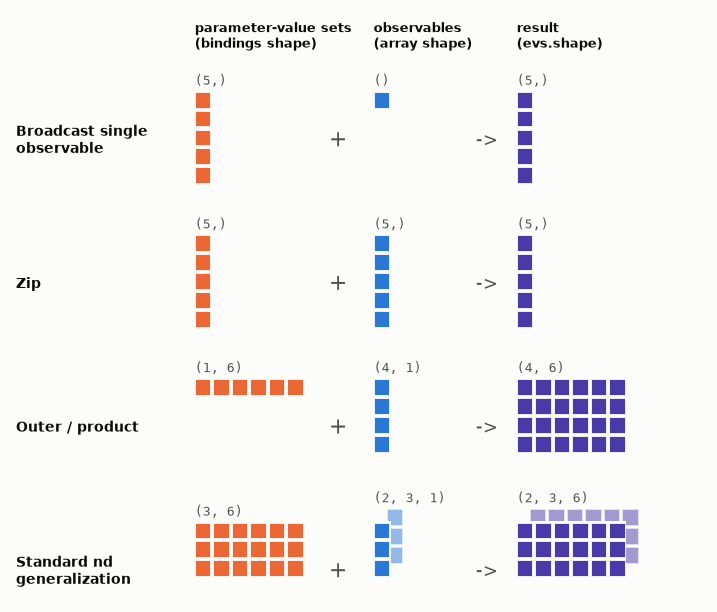

In [14]:
a, b = Parameter("a"), Parameter("b")
qc_ab = QuantumCircuit(2)
qc_ab.ry(a, 0)
qc_ab.cx(0, 1)
qc_ab.rz(b, 1)
aer_estimator = EstimatorV2(mode=AerSimulator())   # ideal simulator; ry, cx, rz are native gates
aer_estimator.options.simulator.seed_simulator = 1

def evs_shape(observables, parameter_values, circuit=qc_ab):
    pub = (circuit, observables, parameter_values)
    return aer_estimator.run([pub]).result()[0].data.evs.shape

rng = np.random.default_rng(0)
cases = {
    "broadcast single observable": ("ZZ", rng.uniform(size=(5, 2))),
    "zip": (["ZZ", "XX", "YY", "ZI", "IZ"], rng.uniform(size=(5, 2))),
    "outer / product": ([["ZZ"], ["XX"], ["YY"], ["ZI"]], rng.uniform(size=(1, 6, 2))),
    "standard nd generalization": ([[["ZZ"], ["XX"], ["YY"]], [["ZI"], ["IZ"], ["XI"]]],
                                   rng.uniform(size=(3, 6, 2))),
}
for name, (obs, vals) in cases.items():
    print(f"{name:27s} observables {str(np.shape(obs)):10s} values {str(vals.shape):10s}"
          f" -> bindings {str(vals.shape[:-1]):7s} -> evs.shape {evs_shape(obs, vals)}")

broadcast single observable observables ()         values (5, 2)     -> bindings (5,)    -> evs.shape (5,)
zip                         observables (5,)       values (5, 2)     -> bindings (5,)    -> evs.shape (5,)
outer / product             observables (4, 1)     values (1, 6, 2)  -> bindings (1, 6)  -> evs.shape (4, 6)


standard nd generalization  observables (2, 3, 1)  values (3, 6, 2)  -> bindings (3, 6)  -> evs.shape (2, 3, 6)


In [15]:
# Incompatible shapes: 3 observables zipped with 5 parameter sets
try:
    evs_shape(["ZZ", "XX", "YY"], rng.uniform(size=(5, 2)))
except ValueError as err:
    print("ValueError:", err)

# Fix 1 (outer product): make the observables a column -> (3, 1) with (5,) -> (3, 5)
print("outer product:", evs_shape([["ZZ"], ["XX"], ["YY"]], rng.uniform(size=(5, 2))))

# A SparsePauliOp is ONE element, however many terms it has
H = SparsePauliOp.from_list([("ZZ", 0.5), ("XX", 0.3), ("IZ", 0.2)])
print("H as one observable:", evs_shape(H, rng.uniform(size=(4, 2))))
print("H's terms as a column:", evs_shape([[term] for term in H], rng.uniform(size=(4, 2))))

ValueError: The observables shape (3,) and the parameter values shape (5,) are not broadcastable.


outer product: (3, 5)
H as one observable: (4,)
H's terms as a column: (3, 4)


The last axis of `parameter_values` is the parameter axis, not a sweep axis. For a 2-parameter circuit, `(5, 2)` means five parameter sets (bindings shape `(5,)`), while `[0.1, 0.2]` is one set (shape `()`). A convenience that often confuses: for a one-parameter circuit the trailing length-1 axis may be omitted, so values of shape `(5,)` and `(5, 1)` both give bindings shape `(5,)`, whereas `(1, 6)` gives `(1, 6)`. The study notebooks' "outer product" example relies on exactly this.

Sampler PUBs broadcast too. There are no observables, so the PUB shape is simply the bindings shape. Each register's `BitArray` gets that shape, and `num_shots` samples are stored per element. `get_counts(loc=i)` picks one element:

In [16]:
t = Parameter("t")
qc_t = QuantumCircuit(1)
qc_t.ry(t, 0)
qc_t.measure_all()
thetas = np.linspace(0, np.pi, 5)

aer_sampler = SamplerV2(mode=AerSimulator())
aer_sampler.options.simulator.seed_simulator = 123
bits = aer_sampler.run([(qc_t, thetas.reshape(5, 1), 400)]).result()[0].data.meas   # shots=400 in the PUB
print("BitArray shape:", bits.shape, "| shots per element:", bits.num_shots)
for i, th in enumerate(thetas):
    p1 = bits.get_counts(loc=i).get("1", 0) / bits.num_shots
    print(f"t = {th:.3f}: P(1) = {p1:.3f}   exact sin^2(t/2) = {np.sin(th / 2) ** 2:.3f}")

BitArray shape: (5,) | shots per element: 400
t = 0.000: P(1) = 0.000   exact sin^2(t/2) = 0.000
t = 0.785: P(1) = 0.133   exact sin^2(t/2) = 0.146
t = 1.571: P(1) = 0.453   exact sin^2(t/2) = 0.500
t = 2.356: P(1) = 0.868   exact sin^2(t/2) = 0.854
t = 3.142: P(1) = 1.000   exact sin^2(t/2) = 1.000


To find a PUB's result shape, write both shapes right-aligned, drop the parameter axis from the values, and broadcast. `(2,3,1)` observables with `(3,6,·)` values: bindings `(3,6)` → `(2,3,6)`. The number of expectation values is the product of the shape, 36 here, and all of them come from one PUB in one job.

### Practice 4.5 — Predict the broadcast shape

`qc_ab` has two parameters. For each PUB `(qc_ab, observables, values)` write the expected `evs.shape` as a tuple, or the string `"error"` if the shapes do not broadcast. Reason it out first; the check runs the PUBs.

In [ ]:
# observables                         values shape
ex5_predictions = {
    "a": None,   # "ZZ"                              (7, 2)
    "b": None,   # [["ZZ"], ["XX"]]                  (1, 7, 2)
    "c": None,   # ["ZZ", "XX", "YY"]                (7, 2)
    "d": None,   # [["ZZ", "XX", "YY"]]              (4, 1, 2)
    "e": None,   # [[["ZZ"]], [["XX"]]]              (3, 5, 2)
}

In [ ]:
# Run this cell to check your answer
ex5_cases = {
    "a": ("ZZ", (7, 2)),
    "b": ([["ZZ"], ["XX"]], (1, 7, 2)),
    "c": (["ZZ", "XX", "YY"], (7, 2)),
    "d": ([["ZZ", "XX", "YY"]], (4, 1, 2)),
    "e": ([[["ZZ"]], [["XX"]]], (3, 5, 2)),
}
for key, (obs, vshape) in ex5_cases.items():
    try:
        actual = evs_shape(obs, np.zeros(vshape))
    except ValueError:
        actual = "error"
    assert ex5_predictions[key] == actual, f"case {key}: expected {actual}, got {ex5_predictions[key]}"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex5_predictions = {
    "a": (7,),        # () with (7,)
    "b": (2, 7),      # (2, 1) with (1, 7)
    "c": "error",     # (3,) with (7,)
    "d": (4, 3),      # (1, 3) with (4, 1)
    "e": (2, 3, 5),   # (2, 1, 1) with (3, 5)
}
```

Drop the last axis (size 2 = number of parameters) from the values, then broadcast right-aligned. (a) `()` with `(7,)` → `(7,)`. (b) `(2,1)` with `(1,7)` → `(2,7)`. (c) `(3,)` with `(7,)`: 3 ≠ 7 and neither is 1 → `ValueError`. (d) `(1,3)` with `(4,1)` → `(4,3)`. (e) `(2,1,1)` with `(3,5)`, which is `(1,3,5)` once padded → `(2,3,5)`.

</details>

### Practice 4.6 — Build an outer-product PUB

Using `qc_ab` with `b = 0` fixed, sweep `a` over the 8 values in `ex6_a`. Build `ex6_observables` (the three observables `"ZZ"`, `"XX"`, `"ZI"` in this order) and `ex6_values` so that one PUB returns `evs.shape == (3, 8)`, where row i belongs to observable i. Run it with `EstimatorV2` on an ideal `AerSimulator()` with `options.default_precision = 0.01` and `options.simulator.seed_simulator = 6`, and store the `evs` array in `ex6_evs`.

In [ ]:
ex6_a = np.linspace(0, np.pi, 8)
ex6_observables = None   # TODO
ex6_values = None        # TODO: last axis = (a, b)
ex6_evs = None           # TODO

In [ ]:
# Run this cell to check your answer
assert np.shape(ex6_evs) == (3, 8), f"evs.shape is {np.shape(ex6_evs)}, expected (3, 8)"
ex6_expected = np.array([
    [Statevector(qc_ab.assign_parameters([av, 0.0])).expectation_value(SparsePauliOp(p)).real
     for av in ex6_a]
    for p in ("ZZ", "XX", "ZI")
])
assert np.allclose(ex6_evs, ex6_expected, atol=0.06), "rows must be ZZ, XX, ZI and columns the 8 values of a"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex6_a = np.linspace(0, np.pi, 8)
ex6_observables = [["ZZ"], ["XX"], ["ZI"]]                  # shape (3, 1)
ex6_values = np.stack([ex6_a, np.zeros_like(ex6_a)], axis=-1)  # shape (8, 2) -> bindings (8,)
ex6_estimator = EstimatorV2(mode=AerSimulator())
ex6_estimator.options.default_precision = 0.01                # about 10,000 shots per value
ex6_estimator.options.simulator.seed_simulator = 6
ex6_evs = ex6_estimator.run([(qc_ab, ex6_observables, ex6_values)]).result()[0].data.evs
print(ex6_evs.shape)
```

Observables of shape `(3, 1)` broadcast against bindings of shape `(8,)` (values `(8, 2)`) to give `(3, 8)`. With `b = 0` the state is $\cos\frac a2|00\rangle + \sin\frac a2|11\rangle$, so $\langle ZZ\rangle = 1$, $\langle XX\rangle = \sin a$ and $\langle ZI\rangle = \cos a$. Observables `["ZZ", "XX", "ZI"]` (shape `(3,)`) would instead try to zip with `(8,)` and fail.

</details>

### Practice 4.7 — A 2-D parameter scan with one Sampler PUB

> **Optional extension.** Practice 4.7: implement a two-dimensional scan. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s4-resume-69). Later core code does not require this block.

`ex7_qc` applies $R_Y(a)$ to qubit 0 and $R_Y(b)$ to qubit 1 and measures both, so $P(00) = \cos^2\frac a2 \cos^2\frac b2$.

1. Build `ex7_values` with shape `(3, 4, 2)` so that element `[i, j]` binds `a = ex7_as[i]`, `b = ex7_bs[j]` (hint: `np.meshgrid(..., indexing="ij")`).
2. Run one PUB with `SamplerV2` on an ideal `AerSimulator()` (`options.simulator.seed_simulator = 7`) and 4000 shots per element.
3. Store the measured probabilities of `'00'` in the `(3, 4)` array `ex7_p00`.

In [ ]:
ex7_a, ex7_b = Parameter("a"), Parameter("b")
ex7_qc = QuantumCircuit(2)
ex7_qc.ry(ex7_a, 0)
ex7_qc.ry(ex7_b, 1)
ex7_qc.measure_all()
ex7_as = np.array([0.0, np.pi / 2, np.pi])
ex7_bs = np.linspace(0, np.pi, 4)

ex7_values = None   # TODO: shape (3, 4, 2)
ex7_p00 = None      # TODO: shape (3, 4)

In [ ]:
# Run this cell to check your answer
assert np.shape(ex7_values) == (3, 4, 2), f"ex7_values.shape is {np.shape(ex7_values)}, expected (3, 4, 2)"
assert [p.name for p in ex7_qc.parameters] == ["a", "b"]
exact = np.outer(np.cos(ex7_as / 2) ** 2, np.cos(ex7_bs / 2) ** 2)
assert np.shape(ex7_p00) == (3, 4) and np.allclose(ex7_p00, exact, atol=0.04), ex7_p00
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex7_a, ex7_b = Parameter("a"), Parameter("b")
ex7_qc = QuantumCircuit(2)
ex7_qc.ry(ex7_a, 0)
ex7_qc.ry(ex7_b, 1)
ex7_qc.measure_all()
ex7_as = np.array([0.0, np.pi / 2, np.pi])
ex7_bs = np.linspace(0, np.pi, 4)

A, B = np.meshgrid(ex7_as, ex7_bs, indexing="ij")          # each (3, 4)
ex7_values = np.stack([A, B], axis=-1)                     # (3, 4, 2); parameter order = qc.parameters
ex7_sampler = SamplerV2(mode=AerSimulator())
ex7_sampler.options.simulator.seed_simulator = 7
ex7_bits = ex7_sampler.run([(ex7_qc, ex7_values, 4000)]).result()[0].data.meas
ex7_p00 = np.array([[ex7_bits.get_counts(loc=(i, j)).get("00", 0) / 4000 for j in range(4)]
                    for i in range(3)])
print(ex7_bits.shape)
```

The values array `(3, 4, 2)` has bindings shape `(3, 4)`, so the `BitArray` has shape `(3, 4)` with 4000 shots in each element. The last axis follows `qc.parameters`, which Qiskit sorts by name (`a`, `b`). `get_counts(loc=(i, j))` returns the counts of a single grid point. Twelve circuits' worth of data came back from a single PUB.

</details>

<a id="s4-resume-69"></a>

Q4.7. `qc` has exactly two parameters. What is `result[0].data.evs.shape`?

```python
estimator = EstimatorV2(mode=AerSimulator())
params = np.zeros((10, 2))
observables = [["ZZ"], ["XX"], ["YY"]]
result = estimator.run([(qc, observables, params)]).result()
```

A. `(10, 3)`

B. `(3, 10, 2)`

C. `(3, 10)`

D. `ValueError`, because 3 and 10 are not compatible

<details>
<summary>Show answer</summary>

Answer: C

The values `(10, 2)` give bindings shape `(10,)`; the last axis runs over the 2 parameters. The observables `[["ZZ"], ["XX"], ["YY"]]` have shape `(3, 1)`. Broadcasting `(3, 1)` with `(10,)` gives `(3, 10)`: one row per observable, one column per parameter set. B wrongly keeps the parameter axis. D would be right for observables of shape `(3,)`; the inner lists turn it into an outer product.

</details>

Q4.8. `qc` has exactly two parameters. What happens?

```python
params = np.random.rand(5, 2)
observables = ["ZZ", "XX", "YY", "ZI"]
job = EstimatorV2(mode=AerSimulator()).run([(qc, observables, params)])
```

A. A `ValueError`: observables shape `(4,)` and parameter values shape `(5,)` are not broadcastable

B. `evs.shape == (4, 5)`

C. `evs.shape == (5, 4)`

D. `evs.shape == (20,)`

<details>
<summary>Show answer</summary>

Answer: A

Right-aligned, `(4,)` meets `(5,)`: the sizes differ and neither is 1, so the PUB is invalid. Qiskit raises the `ValueError` when it builds the PUB (verified). An outer product (B) needs observables of shape `(4, 1)`. The primitives never flatten shapes (D).

</details>

Q4.9. `qc` has exactly two parameters. What is `evs.shape`?

```python
H = SparsePauliOp.from_list([("ZZ", 0.5), ("XX", 0.5)])
res = EstimatorV2(mode=AerSimulator()).run([(qc, H, np.zeros((8, 2)))]).result()
evs = res[0].data.evs
```

A. `(2, 8)`

B. `(8, 2)`

C. `(16,)`

D. `(8,)`

<details>
<summary>Show answer</summary>

Answer: D

A `SparsePauliOp` is a single observable (shape `()`) no matter how many Pauli terms it contains. The Estimator returns $\langle H\rangle$, the weighted sum of the terms, for each of the 8 parameter sets. Getting the terms separately would require a list of single-term operators, for example `[[t] for t in H]` for a `(2, 8)` outer product.

</details>

<a id="s4-core-76"></a>

## Section review — exam-style questions

First pass: answer the unmarked questions. Items labelled **Optional extension** or **Deeper API practice** are a separate second pass; they are not prerequisites for moving to the next notebook.

Start with the unmarked questions before opening their folds. As on the exam, "Select two" questions need both letters.

Q4.10. Which two workloads are better served by session mode than by batch mode? (Select two.)

A. A VQE loop in which a classical optimizer chooses the next parameters from the previous energy estimate

B. 500 independent circuits, all available before submission, split into 5 jobs of 100 PUBs

C. Learning a noise model once for PEA/PEC and then reusing it for several follow-up jobs before it goes stale

D. A single Sampler job with 20 PUBs

E. Any workload on an Open Plan instance, to minimise cost

<details>
<summary>Show answer</summary>

Answer: A, C

Sessions are for iterative or dependent jobs (A) and for experiments that must run tightly together on a device that stays the same, such as reusing a learned noise model (C). Independent, ready jobs (B) are the textbook batch case. A single job (D) gains nothing from batch or session, since neither shortens the first job's queue time. Open Plan instances (E) cannot open sessions at all.

</details>

Q4.11. `backend` is a valid backend object and `isa_qc` a valid ISA circuit. What is `sampler.mode` right after the job is submitted?

```python
with Batch(backend=backend) as batch:
    sampler = SamplerV2()
    job = sampler.run([isa_qc])
```

A. `None`: without a `mode` argument the sampler runs in job mode

B. The `Batch` object `batch`

C. The backend object, because the batch only wraps it

D. Nothing: `SamplerV2()` raises `ValueError` because no mode was given

<details>
<summary>Show answer</summary>

Answer: B

Inside a `Session`/`Batch` context manager a primitive created without `mode` picks up the active context, so `sampler.mode is batch` (verified). Outside any context manager, `SamplerV2()` does raise `ValueError: A backend or session must be specified` (D), but not here. Job mode (A) applies only when the primitive gets a backend and no context is active at construction time.

</details>

Q4.12. In which mode does the job run?

```python
sampler = SamplerV2(mode=backend)
with Session(backend=backend) as session:
    job = sampler.run([isa_qc])
```

A. In the session, because `run()` is called inside the `with` block

B. In a batch, because no `mode=session` was given

C. Nowhere: `run()` raises because two modes are active

D. In job mode, because the primitive was created before the session context was opened

<details>
<summary>Show answer</summary>

Answer: D

The mode is fixed when the primitive is constructed. At that point no session was open, so `sampler.mode` is `None` and the job runs in job mode. Runtime even logs a warning that the job runs in job mode although a session context manager is open. Create the primitive inside the block, or pass `mode=session`, to use the session. (A related detail: an `IBMBackend` passed as `mode` while a session context is already open is redirected into that session, again with a warning.)

</details>

Q4.13. Outside of an active batch or session, how does the IBM Quantum scheduler pick the next workload for a QPU?

A. Strict first-in-first-out across all users

B. Shortest estimated QPU time first

C. From the instance that has used the least of its allocation within the rolling scheduling window, then first-in-first-out within that instance

D. Paid-plan jobs always run before Open Plan jobs, then in random order

<details>
<summary>Show answer</summary>

Answer: C

The fair-share scheduler balances instances by allocation versus usage over a rolling window (28 days, per the IBM documentation) and is FIFO within one instance. Completion order therefore need not match submission order. Global FIFO (A) and shortest-first (B) are not how it works, and D is not a documented rule.

</details>

Q4.14. How is usage (what your instance is charged) measured for a session compared with a batch?

A. Session: wall-clock time while the session is active, including idle time between jobs. Batch: only the time the QPU is locked for the batch's jobs.

B. Both: only the time the QPU spends executing circuits.

C. Session: only QPU execution time. Batch: wall-clock time from the first job to the last.

D. Both: the time from creating the `Session`/`Batch` object until it is closed.

<details>
<summary>Show answer</summary>

Answer: A

A session reserves the QPU, so its whole active window counts, including the interactive-TTL gaps while your classical code runs. That is why you should close a session promptly. Batch usage is the cumulative QPU time of its jobs; compilation is not counted. B ignores the reservation that a session holds, C swaps the two rules, and D is wrong because no timer starts before the first job begins running.

</details>

Q4.15. Which two statements about the Open Plan are correct? (Select two.)

A. It provides up to 10 QPU minutes per rolling 28-day window

B. Open Plan users may open a session as long as `max_time` is at most 10 minutes

C. A batch opened on an Open Plan instance without `max_time` has a default maximum TTL of 10 minutes, counted from when its first job starts

D. The 10-minute quota is reset on the first day of every calendar month

E. Only session jobs count against the Open Plan quota

<details>
<summary>Show answer</summary>

Answer: A, C

A is the Open Plan quota ([Plans overview](https://quantum.cloud.ibm.com/docs/guides/plans-overview)), and C is the default maximum TTL of an Open Plan batch ([Run jobs in a batch](https://quantum.cloud.ibm.com/docs/guides/run-jobs-batch)). They are two different "10 minutes": a usage allowance and a lifetime timer for one batch. B is false because Open Plan users cannot submit session jobs at all, whatever `max_time` is. D is false because the window is rolling (the last 28 days), not a calendar month. E is false: Open Plan instances cannot run sessions, and their job and batch usage is what consumes the quota.

</details>

Q4.16. `qc3` has exactly three parameters. What is `evs.shape`?

```python
observables = ["ZII", "IZI", "IIZ", "XII", "IXI"]
values = np.zeros((4, 1, 3))
evs = EstimatorV2(mode=AerSimulator()).run([(qc3, observables, values)]).result()[0].data.evs
```

A. `(4, 1, 5)`

B. `(5, 4)`

C. `ValueError`, because 5 and 3 do not match

D. `(4, 5)`

<details>
<summary>Show answer</summary>

Answer: D

The last axis (3) of the values is the parameter axis, so the bindings shape is `(4, 1)`. The observables have shape `(5,)`. Right-aligned, `(4, 1)` and `(5,)` give `(4, 5)` (verified). C compares the parameter axis with the observables, which is the classic mistake. A forgets that the size-1 axis stretches to 5.

</details>

Q4.17. `qc` has two parameters and ends with `measure_all()`. What do `shape` and `num_shots` of the returned `BitArray` equal?

```python
sampler = SamplerV2(mode=AerSimulator())
res = sampler.run([(qc, np.zeros((6, 2)), 200)], shots=1000).result()
bits = res[0].data.meas
print(bits.shape, bits.num_shots)
```

A. `(6,) 200`

B. `(6,) 1000`

C. `(6, 2) 200`

D. `() 1200`

<details>
<summary>Show answer</summary>

Answer: A

The PUB's bindings shape is `(6,)`, and the `BitArray` of each register takes that shape. The third PUB element (200 shots) overrides the `run(..., shots=1000)` keyword, which in turn would override `default_shots` (verified: prints `(6,) 200`). C keeps the parameter axis, and D mixes the two shot counts.

</details>

Q4.18. The figure shows the parameter-value sets, the observables and the resulting expectation-value array of one Estimator PUB. Which broadcasting pattern does it show?

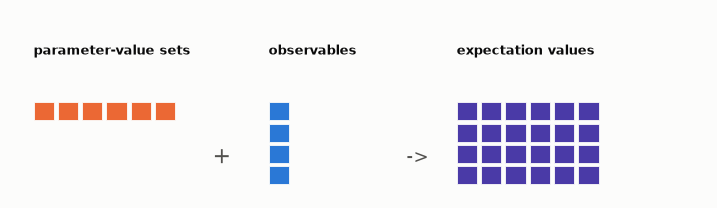

A. Zip

B. Outer / product

C. Broadcast single observable

D. Standard nd generalization

<details>
<summary>Show answer</summary>

Answer: B

A row of 6 parameter sets (bindings shape `(1, 6)`) combined with a column of 4 observables (shape `(4, 1)`) gives every observable at every parameter set, a 4 × 6 grid `(4, 6)`: the outer (product) pattern. Zip pairs equal-length 1-D arrays element by element. The single-observable pattern has an observables array of shape `()`. The nd generalization stacks extra leading axes, for example `(2, 3, 1)` with `(3, 6)` → `(2, 3, 6)`.

</details>

Q4.19. You test code locally, without credentials, in local testing mode. Which two statements are true? (Select two.)

> **Deeper API practice — optional on the first pass.** Exact local-mode service behaviour is deeper API practice; retain the basic distinction between simulation and QPU execution.

A. `Session(backend=AerSimulator())` creates a session on IBM Quantum Platform, so an API key is required

B. `Session`/`Batch` syntax is accepted, but there is no scheduling, so the execution mode has no effect

C. `SamplerV2(mode=AerSimulator.from_backend(FakeManilaV2()))` rejects a circuit containing an `h` gate with the Runtime's `IBMInputValueError`

D. `SamplerV2(mode=FakeManilaV2())` still checks each circuit against the fake backend's target, so a non-ISA circuit raises `IBMInputValueError`

E. `session.details()` returns the same dictionary as on hardware, with `'mode': 'dedicated'`

<details>
<summary>Show answer</summary>

Answer: B, D

Locally, the session is served by the local service: no credentials are needed, no scheduling happens, and `session.session_id` and `session.details()` are `None` (verified), so A and E are false. The Runtime ISA check uses the backend's `Target` and runs when `mode` is a fake backend, so D is true. An `AerSimulator`, including one built with `from_backend`, reports itself as a simulator, so Runtime skips that check. The `h` gate then fails inside Aer with `AerError: unknown instruction: h`, not with `IBMInputValueError` (C is false; verified).

</details>

Q4.20. `qc` has two parameters and `estimator = EstimatorV2(mode=AerSimulator())`. Which one is a valid way to submit a single Estimator PUB?

A. `estimator.run([(qc, [0.1, 0.2], "ZZ")])`

B. `estimator.run((qc, "ZZ", [0.1, 0.2]))`

C. `estimator.run([(qc, "ZZ", [0.1, 0.2], 0.01)])`

D. `estimator.run([(qc, [0.1, 0.2])])`

<details>
<summary>Show answer</summary>

Answer: C

The Estimator PUB order is `(circuit, observables, parameter_values, precision)`, passed inside a list. A swaps the observables and the values (`TypeError: Invalid observable type`). B passes the tuple itself instead of a list of PUBs, so Qiskit tries to read `qc` as a PUB and asks you to wrap it in `[]`. D has no observables; the values are read as observables and rejected. All verified with `EstimatorV2(mode=AerSimulator())`.

</details>

Q4.21. Which two statements describe how today's session and batch modes relate to the dedicated and priority ideas? (Select two.)

A. A batch guarantees that its jobs run in the order they were submitted

B. In session mode, during the active window the QPU runs only your session's jobs; calibration jobs are not interleaved

C. Opening a session moves its first job to the front of the queue

D. Sessions can be interrupted by calibrations and software upgrades

E. Once the first job of a batch starts, the remaining batch jobs are prioritized by the scheduler, but other users' jobs may still run in parallel

<details>
<summary>Show answer</summary>

Answer: B, E

Sessions run in dedicated mode: exclusive access, never interrupted by calibrations or upgrades (B true, D false). Batches keep the priority behaviour without exclusivity: after the first job starts, the other batch jobs jump the queue, yet other users' jobs can fill free execution lanes (E). Batch order is not guaranteed (A), and neither mode shortens the first job's queue time (C).

</details>

## Cheat sheet

Use this as a reference. It includes optional APIs as well as the core workflow; it is not a list of details to memorise in one pass.

Execution modes

| | Job | Batch | Session |
|---|---|---|---|
| Code | `SamplerV2(mode=backend)` | `with Batch(backend=b, max_time="1h"):` / `mode=batch` | `with Session(backend=b, max_time="1h"):` / `mode=session` |
| Access | shared | shared; remaining jobs prioritized after the first starts | dedicated (exclusive, no calibrations) |
| Order | n/a | not guaranteed | not imposed: simultaneous jobs run in parallel; sequential only if your code waits |
| Usage | QPU time of the job | QPU time of all jobs | active wall-clock time (idle gaps included) |
| Open Plan | yes | yes (default max TTL 10 min) | no |
| Use for | one request (many PUBs OK) | independent, ready jobs | iterative / dependent jobs |

Plans

| Plan | Fact |
|---|---|
| Open Plan | 10 QPU minutes per rolling 28-day window; job and batch only (no sessions); batch default max TTL 10 min, a different "10 minutes" |
| Paid plans | Flex, Pay-As-You-Go, Premium, On-Prem; all three modes |

Lifecycle

| Item | Fact |
|---|---|
| `Session(backend, max_time=None, *, create_new=True)` | `backend` is a backend object; `max_time` in s or `"2h 30m 40s"`; `Batch` has the same signature and subclasses `Session` |
| max TTL | starts when the first job starts; at expiry queued jobs fail and the running job finishes; defaults 8 h (paid), batch 10 min (Open) |
| interactive TTL | not configurable (session 60 s on Premium, batch 1 min); `details()['interactive_timeout']` in seconds; expiry deactivates the workload (`Pending`) |
| `close()` / leaving `with` | no new jobs; submitted jobs finish; a later `run()` raises `IBMRuntimeError('The session is closed.')` |
| `cancel()` | cancels pending jobs |
| `status()` | `Pending`, `In progress, accepting new jobs`, `In progress, not accepting new jobs`, `Closed` |
| `details()["mode"]` | `'dedicated'` (session) or `'batch'` |
| primitive created outside `with` | keeps its own mode (job mode for `mode=backend`) |
| local testing mode | `AerSimulator` (ideal or `from_backend`) or a fake backend: modes ignored, `session_id`/`details()` are `None`; the Runtime ISA check applies to fake backends, while Aer raises `AerError` for unknown instructions |

Service and hardware

| Call | Note |
|---|---|
| `QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token=..., instance=..., name=..., set_as_default=True, overwrite=True)` | saved in `~/.qiskit/qiskit-ibm.json` |
| `QiskitRuntimeService()` / `QiskitRuntimeService(name="my-account")` | load a saved account |
| `service.least_busy(operational=True, simulator=False, min_num_qubits=127)` | fewest pending jobs |
| `service.backend("ibm_torino")`, `service.backends(**filters)` | one by name / a list |
| `generate_preset_pass_manager(optimization_level=1, backend=b).run(qc)` | ISA circuit (required) |
| `obs.apply_layout(isa.layout)` | map observables for Estimator |

PUBs and broadcasting

| Rule | Example |
|---|---|
| Estimator PUB `(circuit, observables, values, precision)` | `[(isa, [obs1, obs2], vals)]` |
| Sampler PUB `(circuit, values, shots)` or a bare circuit | `[(isa, vals, 500)]` |
| bindings shape = `values.shape[:-1]` | `(10, 2)` for 2 params → `(10,)` |
| a `SparsePauliOp` is one element | `SparsePauliOp.from_list([...])` → shape `()` |
| result = broadcast(observables, bindings), right-aligned | `(3,1)`+`(10,)` → `(3,10)`; `(4,)`+`(5,)` → error |
| four patterns | single observable `()`+`(5,)`; zip `(5,)`+`(5,)`; outer `(4,1)`+`(1,6)`; nd `(2,3,1)`+`(3,6)` → `(2,3,6)` |
| precedence | PUB value > `run(shots=/precision=)` > `options.default_*` |

## Sources and further reading

Study material this notebook was built from
- Qiskit Advocate KR study group, Section 4: [`Section_4_Run_Quantum_Circuits`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_4_Run_Quantum_Circuits) (`1_Demonstrate_Execution_Modes_KR.ipynb`, `2_Demonstrate_Circuit_Running_RealHW.ipynb`) and [`Review/Practice_10_Qiskit_Primitives.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Review) (Q4–Q5)
- QAMP 2025 textbook: [kibrahim757/qiskit_2x_certification_exam_tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial) (Section 4)

Official documentation (objectives 4.1–4.2)
- [Introduction to execution modes](https://quantum.cloud.ibm.com/docs/guides/execution-modes)
- [Choose the right execution mode](https://quantum.cloud.ibm.com/docs/guides/choose-execution-mode)
- [Run jobs in a session](https://quantum.cloud.ibm.com/docs/guides/run-jobs-session) · [Run jobs in a batch](https://quantum.cloud.ibm.com/docs/guides/run-jobs-batch)
- [Execution modes FAQs](https://quantum.cloud.ibm.com/docs/guides/execution-modes-faq)
- [Get started with the Sampler primitive](https://quantum.cloud.ibm.com/docs/guides/get-started-with-sampler)
- [IBM Quantum patterns](https://quantum.cloud.ibm.com/docs/guides/intro-to-patterns)

Further reading used for facts in this notebook
- [Primitive inputs and outputs (PUBs, broadcasting)](https://quantum.cloud.ibm.com/docs/guides/primitive-input-output)
- [Maximum execution time](https://quantum.cloud.ibm.com/docs/guides/max-execution-time) · [Workload usage](https://quantum.cloud.ibm.com/docs/guides/estimate-job-run-time)
- [Fair-share scheduler](https://quantum.cloud.ibm.com/docs/guides/fair-share-scheduler) · [Plans overview](https://quantum.cloud.ibm.com/docs/guides/plans-overview) · [Save your login credentials](https://quantum.cloud.ibm.com/docs/guides/save-credentials)
- [Local testing mode](https://quantum.cloud.ibm.com/docs/guides/local-testing-mode)
- IBM Quantum blog, [Execution modes for efficient, utility-scale workloads](https://www.ibm.com/quantum/blog/execution-modes) (May 2024: sessions move from prioritized to dedicated access)

First-pass workflow review also consulted the open-source [Quantum Tokyo certification practice notebooks](https://github.com/quantum-tokyo/qiskit-certification-prep): execution-mode selection (Section 4), ISA preparation and default shots (Sections 5–6), and past-job retrieval (Section 7). Their questions were used as a style/reference check, not copied here; the official guide remains the scope reference.

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [Qiskit primitives (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/primitives)
- [SamplerV2 (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/sampler-v2)
- [EstimatorV2 (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/estimator-v2)
- [Session (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/session)
- [Batch (Runtime 0.39)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/batch)
- [Primitive inputs/outputs](https://quantum.cloud.ibm.com/docs/guides/primitive-input-output)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
